# Unfriendly Seating Process

This notebook summarizes and visualizes the results produced by the three
scripts.

1. **Calc_Probabilities**: builds the Padovan sequence, defines the closed-form
   (static) and series-based (sequential) probability functions, and computes
   the full probability matrix `probability_matrix` (rows = total seats,
   columns = number of occupied seats) using a recursive relation.
2. **Calc_ExpectedValues**: computes the expected number of occupied seats for
   both the static and sequential models, across a range of line lengths.
3. **Verify_D_1**: checks the stochastic dominance property (the sequential
   model's dominates the static model's, for a
   fixed n), and stores the cumulative distributions for later plotting.

Below, each result is loaded and plotted for a few representative values of n.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "Source"))

from Calc_Probabilities import (
    padovan_sequence,
    probability_matrix,
    probability_matrix_list,
    possible_indices,
    X_stat,
    X_seq,
    N_stat_k,
    N_seq_k,
)
from Calc_ExpectedValues import (
    expected_seats_sequential,
    expected_seats_static,
)
from Verify_D_1 import accumulated_data

## Occupied-seat count distribution: N_stat vs N_seq

For a fixed line length n, compares the probability of having exactly k
occupied seats, computed with the closed-form formula (N_stat) against the
series expansion (N_seq).

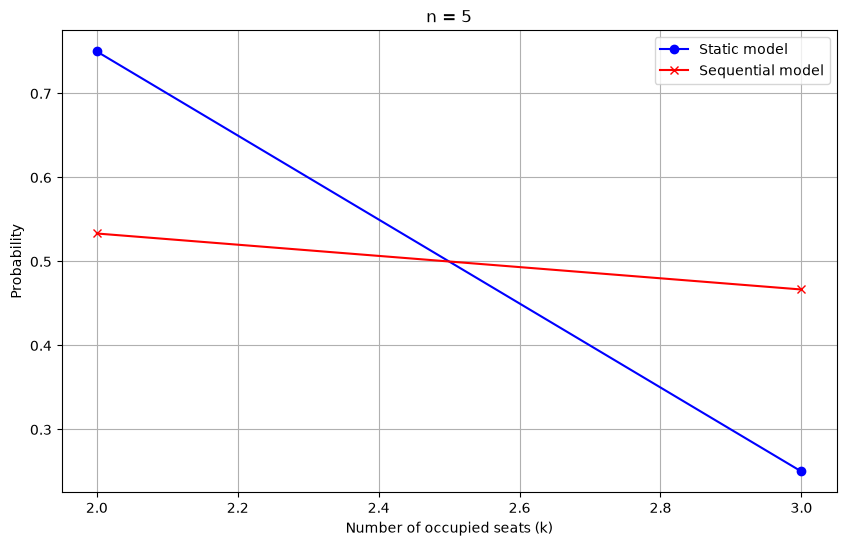

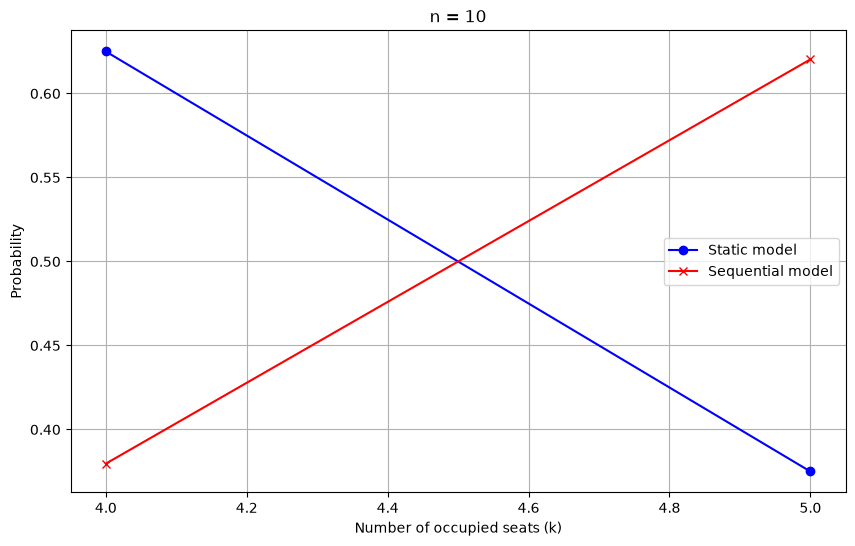

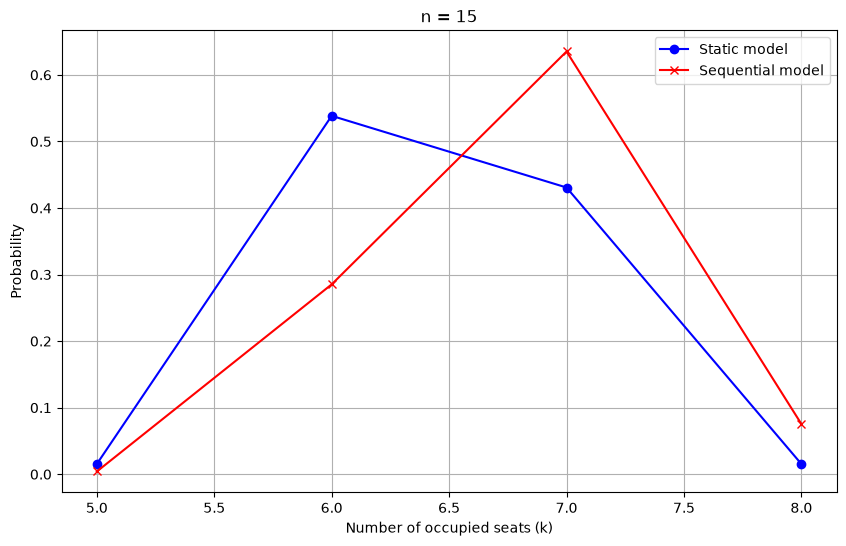

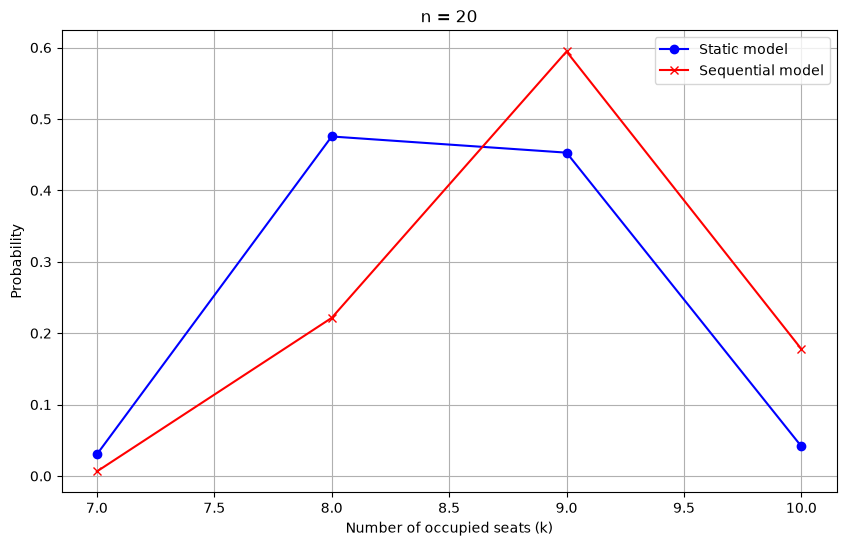

In [6]:
def compare_occupied_count_distributions(n_values):
    """Plot N_stat_k and N_seq_k over the valid k range, for each n in n_values."""
    for n in n_values:
        ks = list(possible_indices(n))
        stat_probs = [N_stat_k(n, k) for k in ks]
        seq_probs = [N_seq_k(n, k) for k in ks]

        plt.figure(figsize=(10, 6))
        plt.plot(ks, stat_probs, color="blue", marker='o', label="Static model")
        plt.plot(ks, seq_probs, color="red", marker='x', label="Sequential model")
        plt.xlabel("Number of occupied seats (k)")
        plt.ylabel("Probability")
        plt.title(f"n = {n}")
        plt.legend()
        plt.grid(True)
        plt.show()


compare_occupied_count_distributions([5, 10, 15, 20])

## Probability matrix

Heatmap of `probability_matrix`: rows are total seats (n), columns are number
of occupied seats (k). Each entry is the probability of exactly k occupied
seats in a line of n seats, computed via the sequential model's recursion.

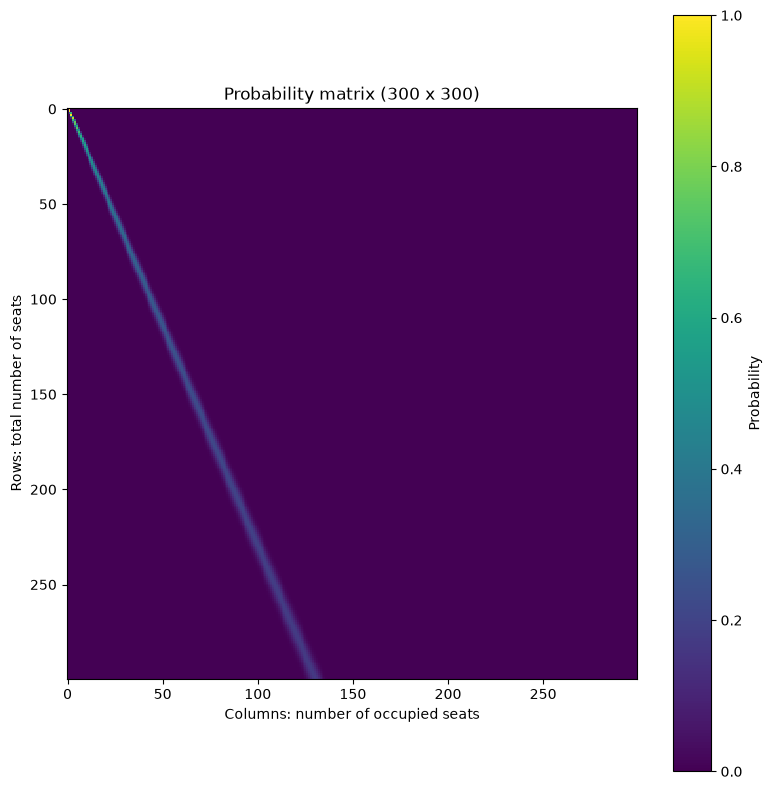

In [7]:
n_rows, n_cols = probability_matrix.shape

plt.figure(figsize=(8, 8))
plt.imshow(probability_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Probability')
plt.title(f'Probability matrix ({n_rows} x {n_cols})')
plt.xlabel('Columns: number of occupied seats')
plt.ylabel('Rows: total number of seats')
plt.tight_layout()
plt.show()

## Expected number of occupied seats

Compares the expected number of occupied seats between the static and
sequential models, as the total number of seats grows.

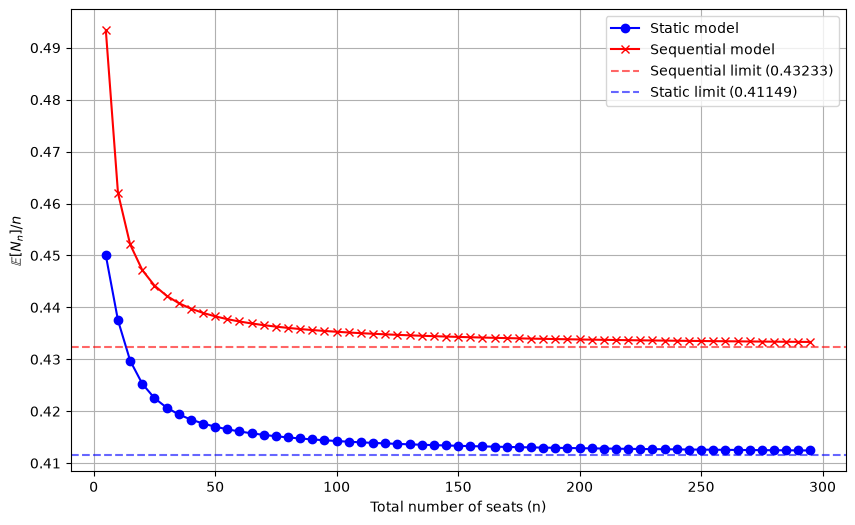

In [8]:
n_values_expected = list(range(5, len(probability_matrix), 5))

expected_seats_static_plot = []
expected_seats_sequential_plot = []
for n in n_values_expected:
    ks = list(possible_indices(n))
    expected_seats_static_plot.append(sum(k * float(N_stat_k(n, k)) for k in ks) / n)

    row = probability_matrix[n - 1]
    expected_seats_sequential_plot.append(sum(k * row[k] for k in range(len(row))) / n)

plt.figure(figsize=(10, 6))
plt.plot(n_values_expected, expected_seats_static_plot, label="Static model", marker='o', color="blue")
plt.plot(n_values_expected, expected_seats_sequential_plot, label="Sequential model", marker='x', color="red")
plt.axhline(0.43233, color="red", linestyle="--", alpha=0.6, label="Sequential limit (0.43233)")
plt.axhline(0.41149, color="blue", linestyle="--", alpha=0.6, label="Static limit (0.41149)")
plt.xlabel("Total number of seats (n)")
plt.ylabel(r"$\mathbb{E}[N_n]/n$")
plt.legend()
plt.grid(True)
plt.show()

## Cumulative distributions: static vs sequential

For each selected n, compares the cumulative distribution of occupied seats
between the two models. This is the data underlying the D_1 property check.

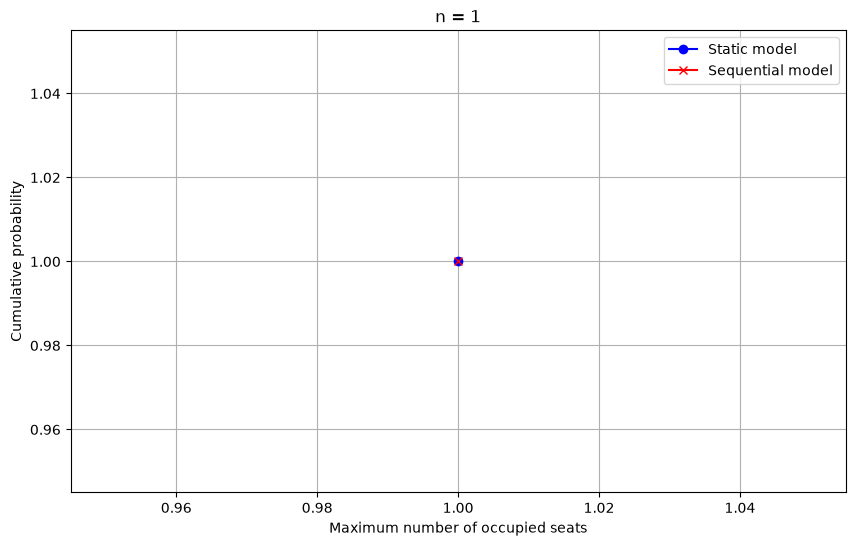

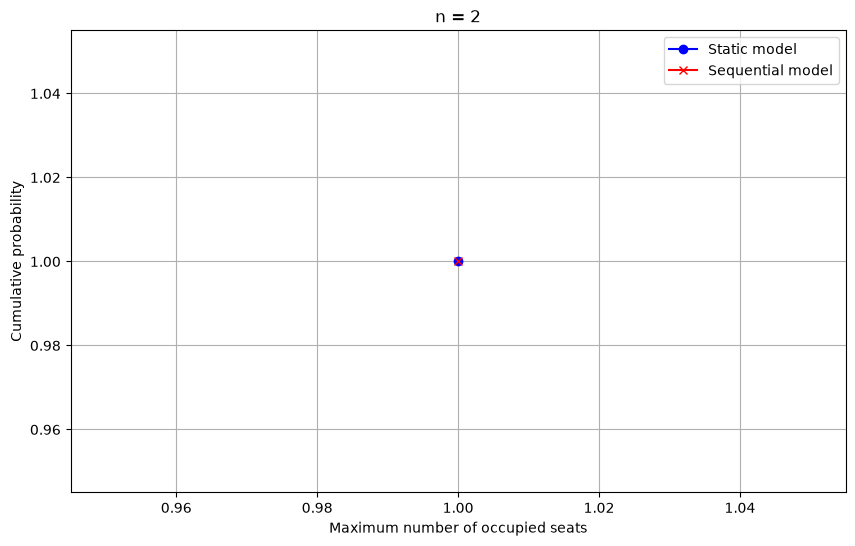

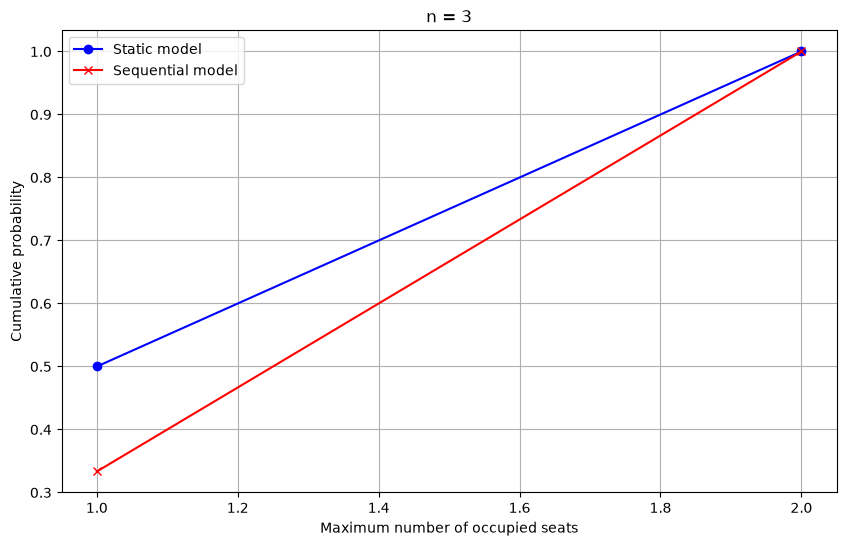

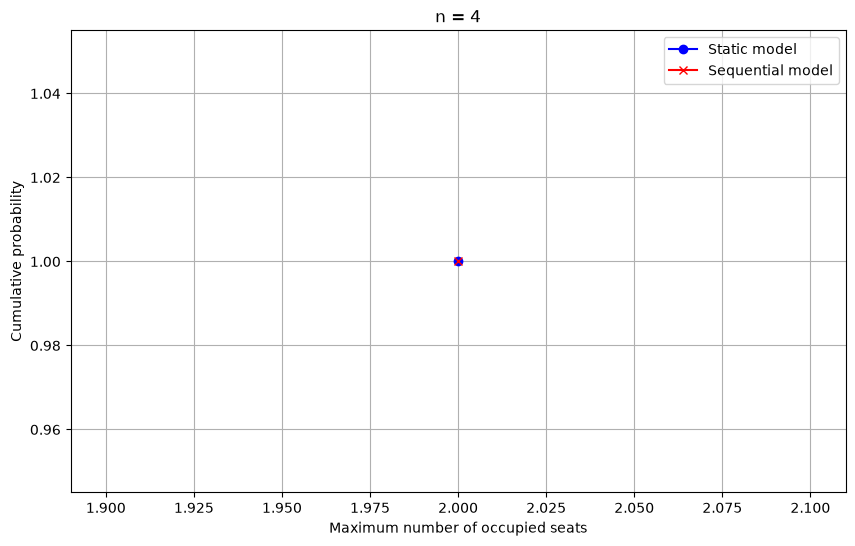

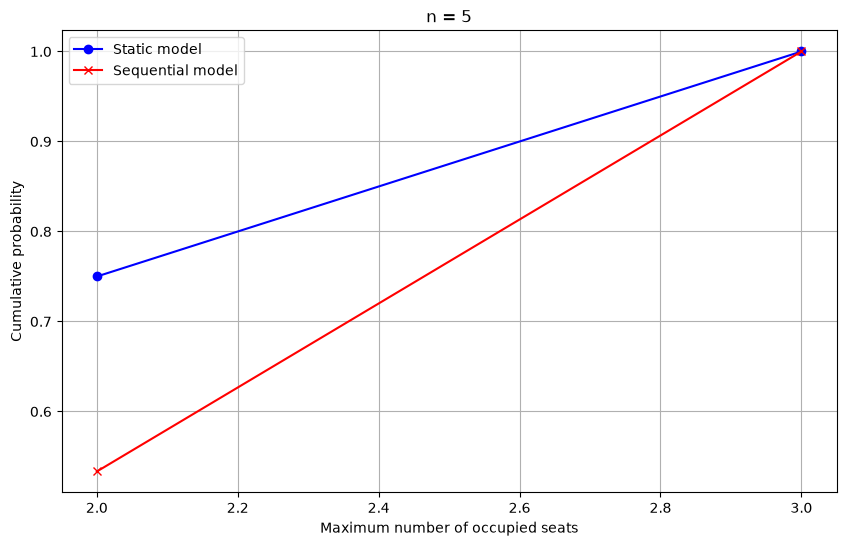

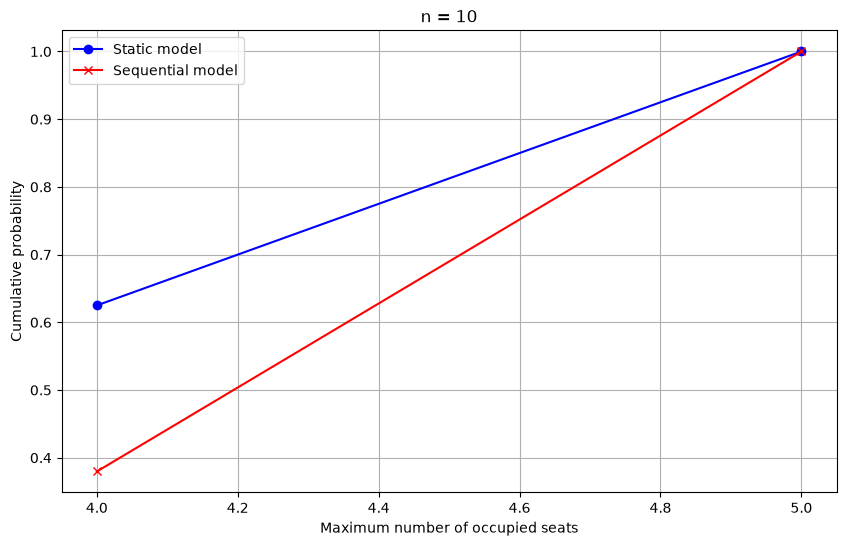

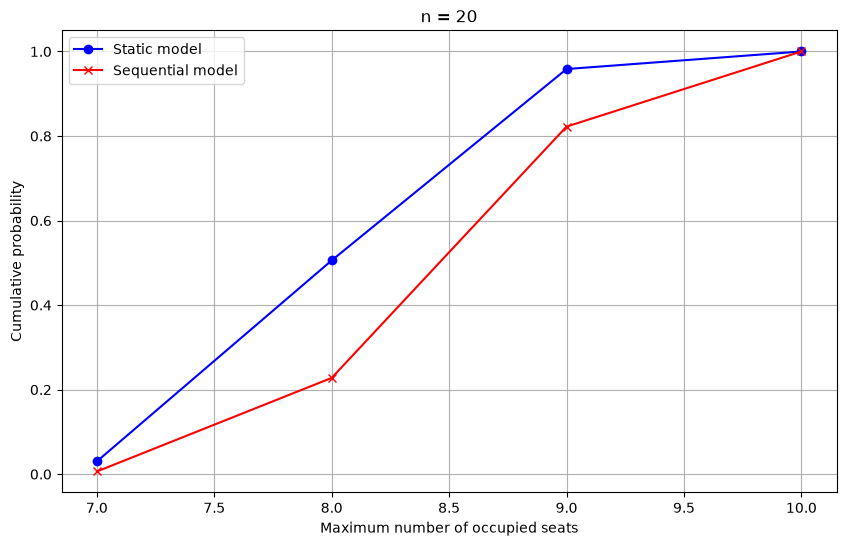

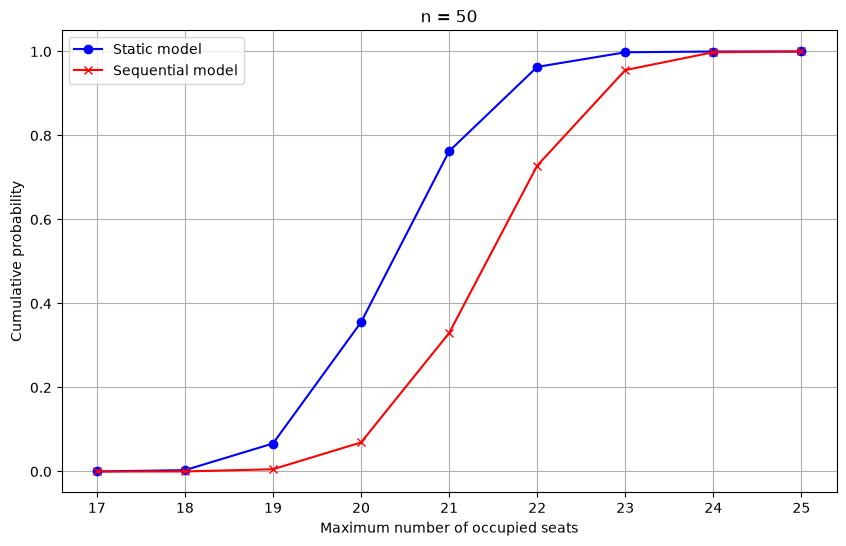

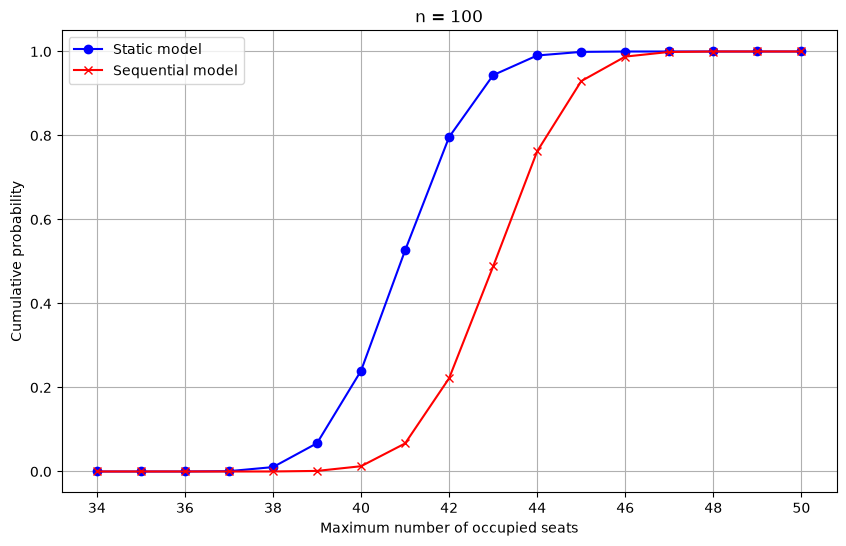

In [9]:
for n in [1, 2, 3, 4, 5, 10, 20, 50, 100]:
    data = accumulated_data[n]

    plt.figure(figsize=(10, 6))
    plt.plot(data["ks"], data["cumulative_stat"], label="Static model", marker='o', color="blue")
    plt.plot(data["ks"], data["cumulative_seq"], label="Sequential model", marker='x', color="red")
    plt.xlabel("Maximum number of occupied seats")
    plt.ylabel("Cumulative probability")
    plt.title(f"n = {n}")
    plt.legend()
    plt.grid(True)
    plt.show()

## Table


In [13]:
import numpy as np
import pandas as pd
from IPython.display import display
from Calc_Probabilities import possible_indices, N_stat_k, probability_matrix, X_stat

def fmt(p):
    if p >= 1 - 1e-12:
        return "1.00000"
    if p < 5e-5:
        mant, exp = f"{p:.2e}".split("e")
        return f"{mant} × 10^{int(exp)}"
    return f"{p:.5f}"

def build_table(ns):
    rows = []
    for n in ns:
        ks = list(possible_indices(n))

        stat_probs = np.array([float(N_stat_k(n, k)) for k in ks])
        seq_probs = np.array(probability_matrix[n - 1][ks[0]:ks[0] + len(ks)], dtype=float)

        cum_stat = np.cumsum(stat_probs)
        cum_seq = np.cumsum(seq_probs)

        E_stat = float(np.dot(ks, stat_probs)) / n
        E_seq = float(np.dot(ks, seq_probs)) / n

        for i, k in enumerate(ks):
            rows.append({
                "n": n if i == 0 else "",
                "k": k,
                "P[N_seq ≤ k]": fmt(cum_seq[i]),
                "P[N_stat ≤ k]": fmt(cum_stat[i]),
                "E[N_seq]/n": f"{E_seq:.5f}" if i == 0 else "",
                "E[N_stat]/n": f"{E_stat:.5f}" if i == 0 else "",
            })

  
    seq_limit = (1 - np.exp(-2)) / 2   
    n_big = 400
    stat_limit = X_stat(n_big, n_big // 2)  
    rows.append({
        "n": "∞", "k": "–", "P[N_seq ≤ k]": "–", "P[N_stat ≤ k]": "–",
        "E[N_seq]/n": f"{seq_limit:.5f}",
        "E[N_stat]/n": f"{stat_limit:.5f}",
    })
    return pd.DataFrame(rows)

table = build_table([20, 25, 30, 50])
display(table.style.hide(axis="index"))


n,k,P[N_seq ≤ k],P[N_stat ≤ k],E[N_seq]/n,E[N_stat]/n
20,7,0.00631,0.03019,0.44718,0.42528
,8,0.22778,0.50566,,
,9,0.82227,0.95849,,
,10,1.00000,1.00000,,
25,9,0.00721,0.04163,0.44421,0.42253
,10,0.18267,0.46901,,
,11,0.71704,0.92692,,
,12,0.98778,0.99907,,
,13,1.00000,1.00000,,
30,10,1.69 × 10^-5,0.00023,0.44223,0.42070


## Stochastic Domination verification

In [17]:
import numpy as np
from Calc_Probabilities import possible_indices, N_stat_k, probability_matrix

TOLERANCE = 1e-10
max_n = len(probability_matrix)

failures = []

for n in range(1, max_n + 1):
    ks = list(possible_indices(n))

    stat_probs = np.array([float(N_stat_k(n, k)) for k in ks])
    seq_probs = np.array(probability_matrix[n - 1][ks[0]:ks[0] + len(ks)], dtype=float)

    cum_stat = np.cumsum(stat_probs)
    cum_seq = np.cumsum(seq_probs)

    diff = cum_stat - cum_seq             

    if not np.all(diff >= -TOLERANCE):
        failures.append(n)

print(f"D_1 verification for n = 1, ..., {max_n}")
print(f"Tolerance: {TOLERANCE}")

if failures:
    print(f"\nD_1 FAILS for {len(failures)} values of n: {failures}")
else:
    print("\nD_1 holds for all n.")


D_1 verification for n = 1, ..., 300
Tolerance: 1e-10

D_1 holds for all n.
